# Analysis results

## 6. Lollipop plot of correlations per metric

- **x-axis:** subgroup ρ (9–11 bins) or subgroup partial ρ | LOC
- **y-axis:** metrics
- **columns:** agent + dataset (verified / live)

The subgroup estimate sorts tasks by the metric, forms ~10 groups, and
correlates each group's **median metric** against its **mean resolve-rate** —
this averages out the per-instance noise of the binary `resolved` outcome and
exposes the trend (so |ρ| is much larger than the per-instance sample ρ).

Sign is encoded by colour (teal = positive, red = negative) and redundantly by
position around the zero line. Significant cells (p < 0.05) are drawn solid, the
rest faded. Empty rows are metrics that are perfectly LOC-rank-collinear, so
their partial correlation is undefined.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
from code_complexity.analysis.swe_analysis import (
    LOLLIPOP_METRICS_NO_DUPLICATES,
    per_metric_agent_correlations,
    lollipop_correlations,
    lollipop_loc_collinearity,
    lm_cc_distribution,
)

### Whole-file — subgroup partial ρ | LOC

Size-adjusted grouped correlation of each metric with `resolved`: the
association that survives after removing raw size, on ~10 bins.

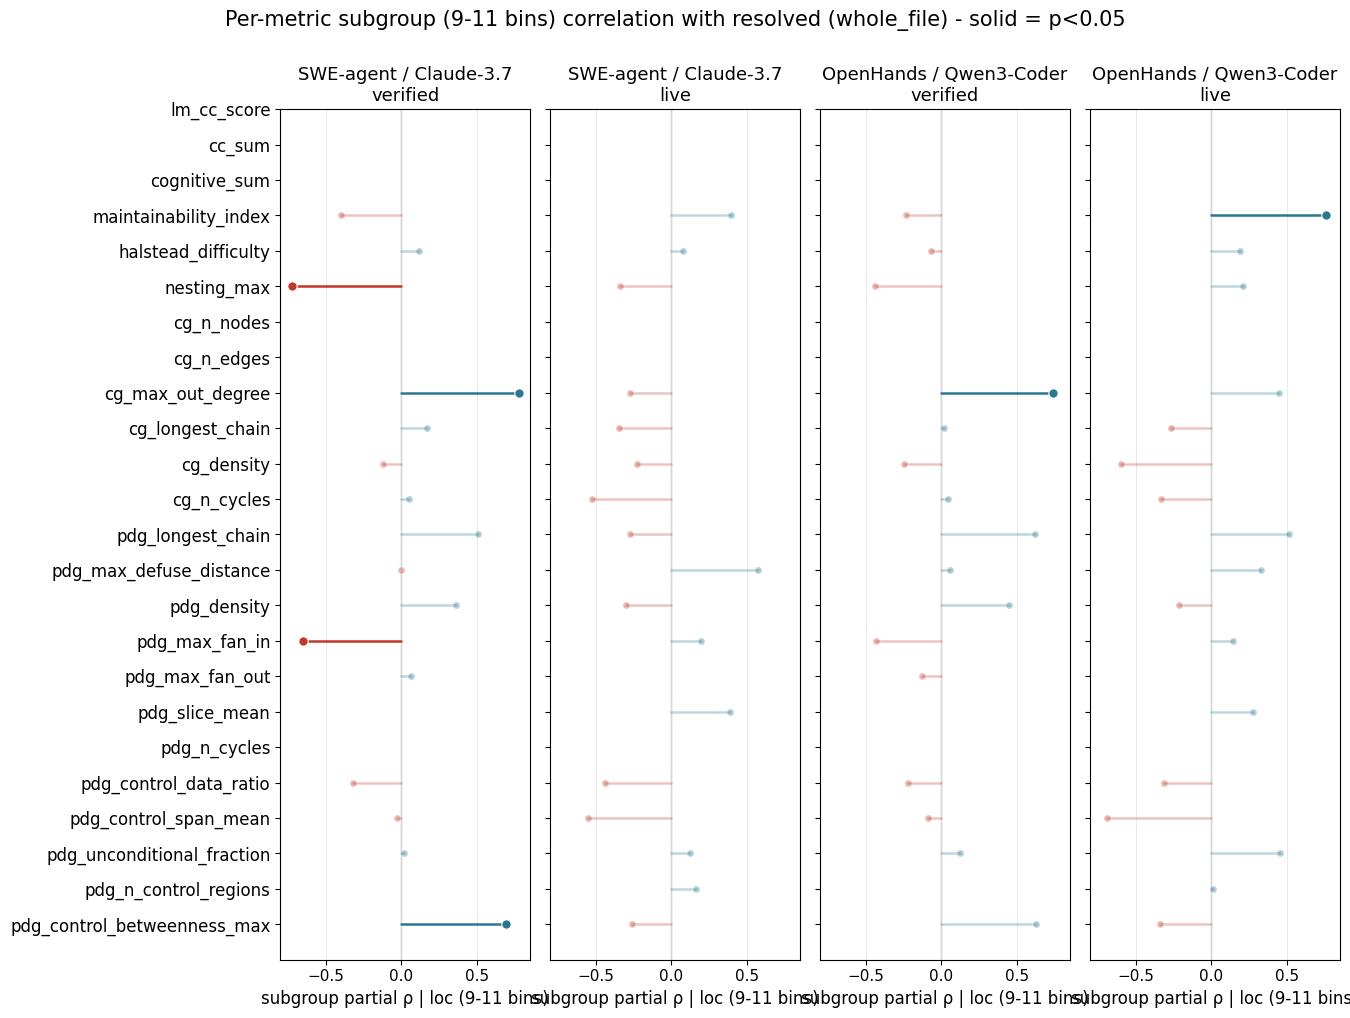

In [2]:
table = per_metric_agent_correlations(
    level="whole_file", metrics=LOLLIPOP_METRICS_NO_DUPLICATES
)
lollipop_correlations(table=table, value="subgroup_partial");

### Whole-file — subgroup ρ (zero-order)

The grouped metric–`resolved` correlation, before controlling for LOC.

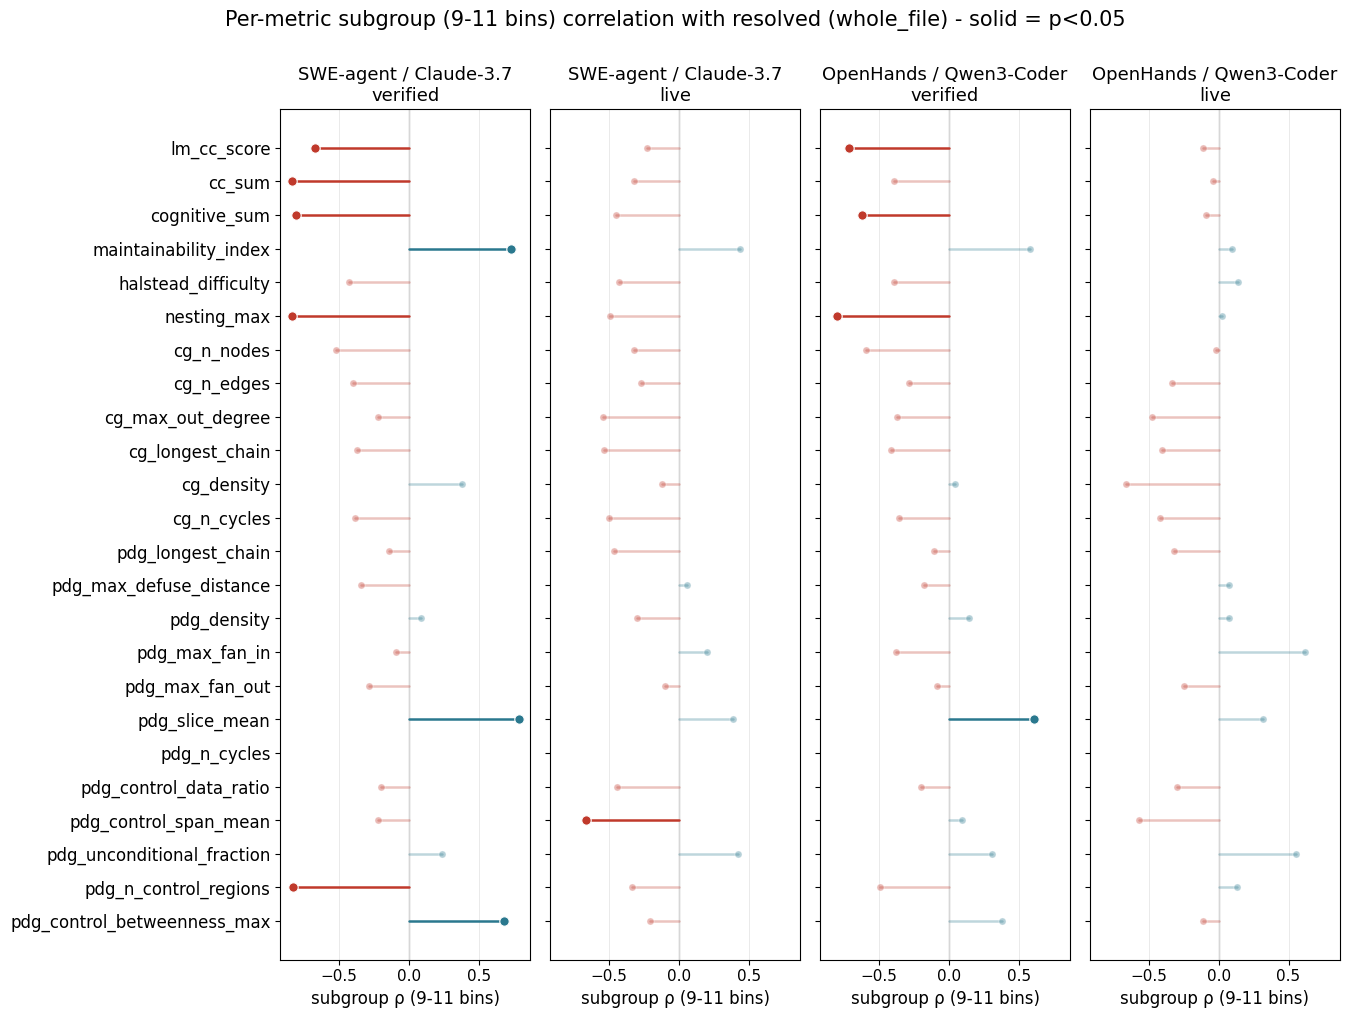

In [3]:
lollipop_correlations(table=table, value="subgroup");

### Function-level — subgroup partial ρ | LOC

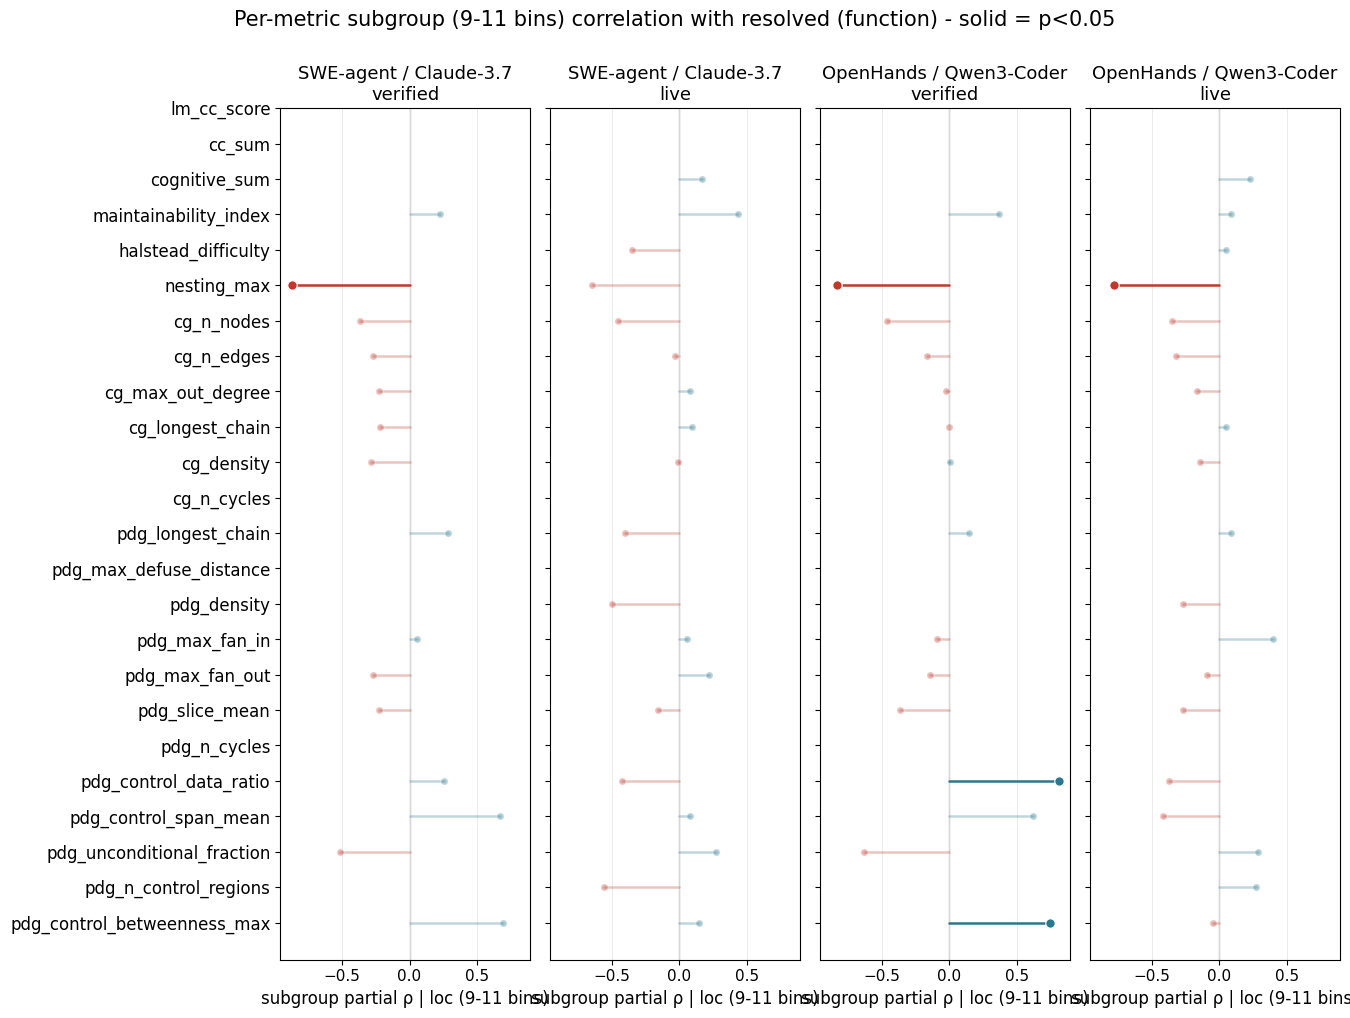

In [4]:
lollipop_correlations(
    level="function", value="subgroup_partial", metrics=LOLLIPOP_METRICS_NO_DUPLICATES
);

### Collinearity with LOC — ρ(metric, LOC)

How strongly each metric tracks raw size. This depends only on the code
metrics, not on the agent, so it is faceted by dataset (Verified / Live) alone.
High |ρ| means the metric is largely redundant with LOC.

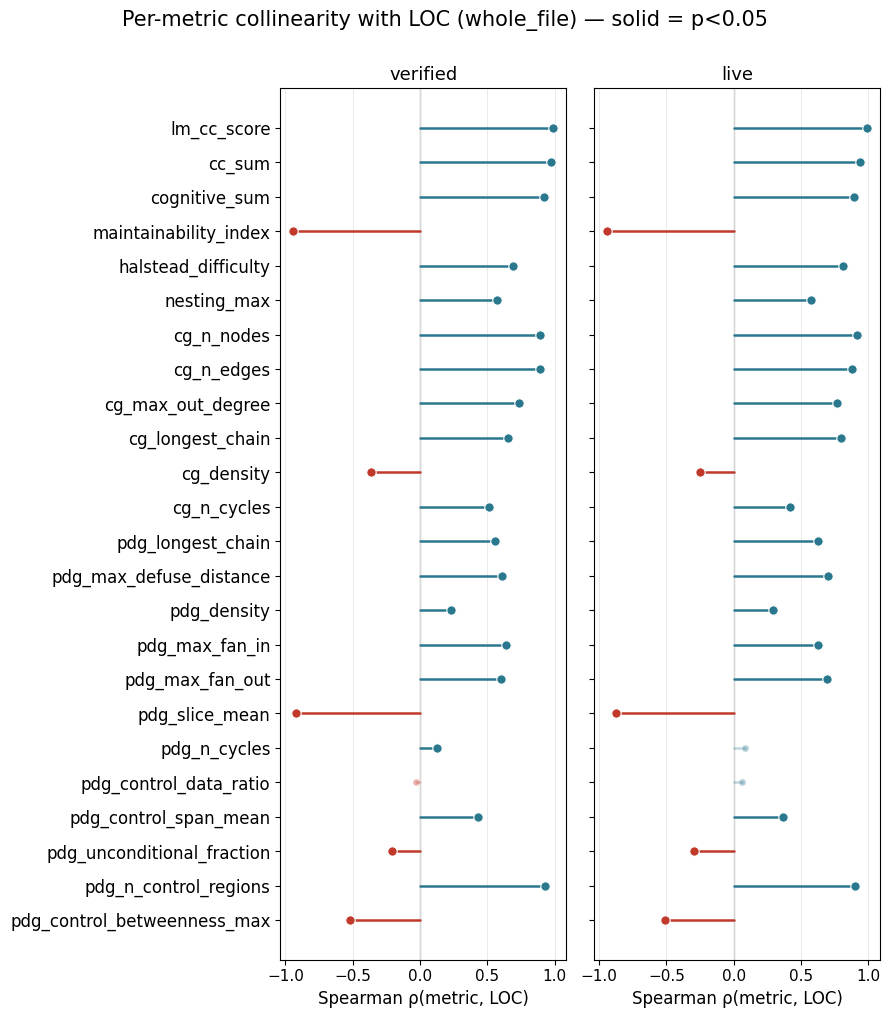

In [5]:
lollipop_loc_collinearity(
    level="whole_file", metrics=LOLLIPOP_METRICS_NO_DUPLICATES
);

## LM-CC distribution — Verified vs Live

One figure for both datasets:

- **left:** density-normalised histogram + KDE
- **right:** box + strip plot for median, spread and outliers

Density (not count) is used because the datasets differ in size
(Verified n=419, Live n=163), so raw counts would not be comparable.

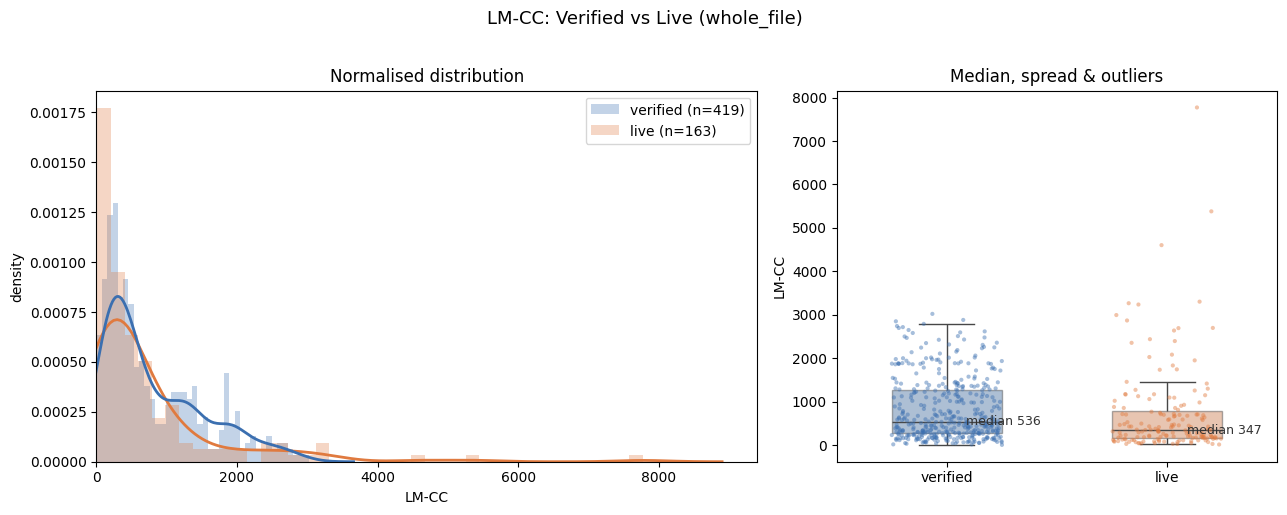

In [6]:
lm_cc_distribution(level="whole_file");